# T33 -- Phase 3: dispersion-aware scoring on real data

**Formula used (exact, per `iste.phase3_dispersion`):**

```text
sigma_iso_sq(t) = trace(Sigma(t)) / 2                     [T30's own covariance, reused]
p_within_r(t)   = 1 - exp(-r^2 / (2*sigma_iso_sq(t)))     [Rayleigh CDF]
D_expected(t)   = N_total_valid_at_t * p_within_r(t)
dispersion_aware_score = D_actual_at_peak / D_expected(t)
```

Compares each candidate's actual local density against what an undifferentiated single
Gaussian blob with the SAME particle count and SAME measured spread would produce at
its own peak. This is the key diagnostic for whether Phase 3 fixes the T28-reported
bias: a lower raw density at T72 should not automatically be read as weaker evidence
than a higher raw density at T1, if T72's own dispersion already explains most of the
difference.

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_initial_bias import compute_timestamp_cloud_stats
from iste.phase3_dispersion import compute_dispersion_aware_score

## 1. Load real Stage III result + T27 grid

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]  # exclude T0 itself, matching earlier real-data notebooks
print(f"loaded {records.n_records} real rows; {len(historical_timestamps)} historical timestamps")

loaded 240024 real rows; 72 historical timestamps


In [3]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

## 2. For each of the 72 real historical timestamps: top candidate's raw density vs. dispersion-aware score

In [4]:
t0 = time.time()
rows = []
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    candidates_here = find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config)
    if not candidates_here:
        continue
    top_candidate = max(candidates_here, key=lambda c: c.support_score)

    cloud_stats = compute_timestamp_cloud_stats(records, t_s)
    disp = compute_dispersion_aware_score(top_candidate, cloud_stats, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M)

    hours_before_obs = float((t_obs - t_s) / np.timedelta64(1, "h"))
    rows.append(dict(
        t_s=t_s, hours_before_obs=hours_before_obs,
        raw_density=top_candidate.density_score, n_total=cloud_stats.n_particles,
        sigma_iso_m=disp.sigma_iso_m, expected_density=disp.expected_density,
        dispersion_aware_score=disp.dispersion_aware_score,
        covariance_state=disp.covariance_state,
    ))
t1 = time.time()
print(f"processed {len(rows)} real historical timestamps in {t1-t0:.1f}s")

processed 72 real historical timestamps in 125.4s


## 3. Raw density vs. dispersion-aware score, side by side, across T0-T72

In [5]:
hours = np.array([r["hours_before_obs"] for r in rows])
raw_density = np.array([r["raw_density"] for r in rows])
dispersion_score = np.array([r["dispersion_aware_score"] for r in rows])

corr_raw = float(np.corrcoef(hours, raw_density)[0, 1])
corr_disp = float(np.corrcoef(hours, dispersion_score)[0, 1])
print(f"correlation(hours_before_obs, raw_density)              = {corr_raw:+.3f}")
print(f"correlation(hours_before_obs, dispersion_aware_score)    = {corr_disp:+.3f}")
print()
print(f"raw_density        range: [{raw_density.min():.2f}, {raw_density.max():.2f}]  ratio={raw_density.max()/raw_density.min():.2f}x")
print(f"dispersion_score   range: [{dispersion_score.min():.4f}, {dispersion_score.max():.4f}]  ratio={dispersion_score.max()/dispersion_score.min():.2f}x")

correlation(hours_before_obs, raw_density)              = -0.875
correlation(hours_before_obs, dispersion_aware_score)    = +0.863

raw_density        range: [336.00, 2123.00]  ratio=6.32x
dispersion_score   range: [0.8536, 2.6524]  ratio=3.11x


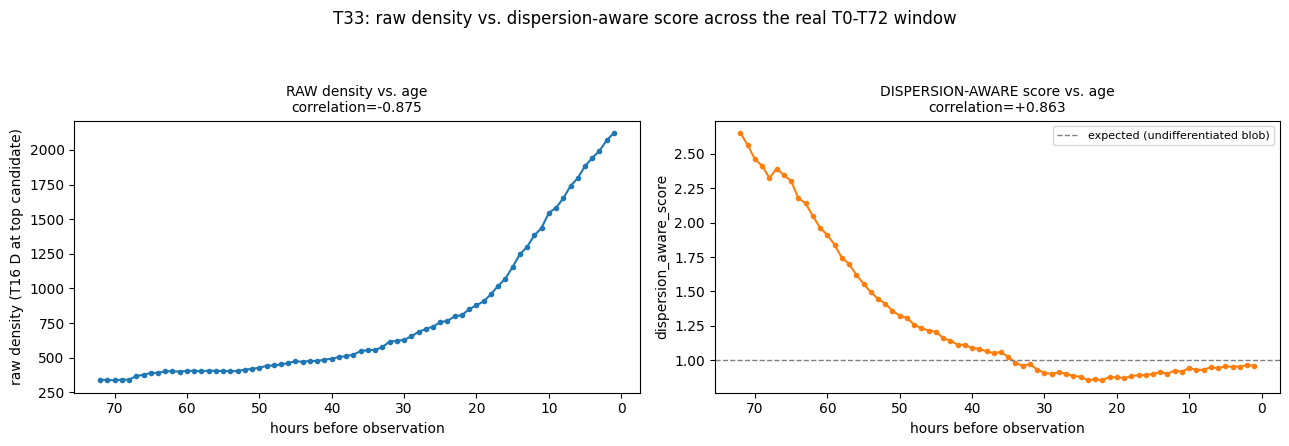

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hours, raw_density, "-o", markersize=3, color="tab:blue")
axes[0].set_xlabel("hours before observation"); axes[0].set_ylabel("raw density (T16 D at top candidate)")
axes[0].set_title(f"RAW density vs. age\ncorrelation={corr_raw:+.3f}", fontsize=10)
axes[0].invert_xaxis()

axes[1].plot(hours, dispersion_score, "-o", markersize=3, color="tab:orange")
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1, label="expected (undifferentiated blob)")
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("dispersion_aware_score")
axes[1].set_title(f"DISPERSION-AWARE score vs. age\ncorrelation={corr_disp:+.3f}", fontsize=10)
axes[1].invert_xaxis()
axes[1].legend(fontsize=8)

fig.suptitle("T33: raw density vs. dispersion-aware score across the real T0-T72 window", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T33_dispersion_vs_raw.png"), dpi=100)
plt.show()

## 4. Sample table

In [7]:
header = f"{'hours_before_obs':>16s} {'raw_density':>12s} {'n_total':>8s} {'sigma_iso_m':>12s} {'expected_D':>11s} {'dispersion_score':>16s}"
print(header); print("-" * len(header))
sample_idx = np.linspace(0, len(rows) - 1, 16).astype(int)
for i in sample_idx:
    r = rows[i]
    print(f"{r['hours_before_obs']:>16.0f} {r['raw_density']:>12.2f} {r['n_total']:>8d} "
          f"{r['sigma_iso_m']:>12.1f} {r['expected_density']:>11.2f} {r['dispersion_aware_score']:>16.4f}")

hours_before_obs  raw_density  n_total  sigma_iso_m  expected_D dispersion_score
--------------------------------------------------------------------------------
               1      2123.00     3288        668.9     2212.37           0.9596
               5      1883.00     3288        739.2     1971.30           0.9552
              10      1545.00     3288        852.5     1635.50           0.9447
              15      1155.00     3288       1006.6     1280.66           0.9019
              19       906.00     3288       1146.6     1040.17           0.8710
              24       766.00     3288       1252.7      897.08           0.8539
              29       653.00     3288       1417.6      724.26           0.9016
              34       557.00     3288       1625.2      567.07           0.9822
              38       511.00     3288       1779.6      480.19           1.0642
              43       477.00     3288       1918.6      417.62           1.1422
              48       444.0

## Known limitations (T33 scope only)

- Isotropic-Gaussian approximation for `expected_density` -- an explicit, documented
  simplification (mirroring T30's own fallback convention), not a claim that real
  particle clouds are exactly isotropic.
- `dispersion_aware_score` is unbounded above -- a likelihood-ratio-style quantity, not
  a probability or a `[0,1]`-normalized value.
- A screening quantity, like every other backward-support diagnostic in this project --
  never proof of physical source identity.
- Not yet combined into T36's final composite score; T34 (screening normalization)
  through T39 not yet implemented.
- No Stage III module, and no existing T14-T17/T25/T26/T30 module, was modified.

## 5. Requested review diagnostic: isotropic vs. anisotropic expected-concentration model

**No changes to `iste/phase3_dispersion.py`.** Purely diagnostic: builds an
ANISOTROPIC alternative to the current isotropic-Rayleigh `D_expected` model, using the
SAME T30 covariance, and compares both against the REAL, model-free empirical
within-radius fraction measured directly from the actual particle positions -- the only
way to judge which model's assumption is statistically appropriate, independent of
which one happens to produce a smaller age correlation (explicitly not the selection
criterion here, per instruction).

**Anisotropic model note:** unlike the isotropic case, the probability mass of a
general anisotropic 2-D Gaussian within a CIRCLE of radius `r` (not an ellipse matched
to its own covariance shape) has no simple closed form -- it is the CDF of the Hoyt
distribution, which requires special functions. For this diagnostic, that probability
is estimated by Monte Carlo (200,000 draws from `N(0, Sigma(t))`, fixed seed) -- an
exact, transparent, dependency-free estimator, clearly labeled as MC, not a new
closed-form claim.

In [8]:
from iste.kdtree_neighborhood import project_to_local_metres

def characterize_anisotropy(cov):
    eigvals, eigvecs = np.linalg.eigh(cov)  # ascending: eigvals[0] <= eigvals[1]
    lam2, lam1 = float(eigvals[0]), float(eigvals[1])  # lam1 = major, lam2 = minor
    axis_ratio = np.sqrt(lam1 / lam2) if lam2 > 0 else np.inf
    major_vec = eigvecs[:, 1]
    orientation_deg = float(np.degrees(np.arctan2(major_vec[1], major_vec[0])) % 180.0)
    det = lam1 * lam2
    return lam1, lam2, axis_ratio, orientation_deg, det

def p_within_r_isotropic(cov, r):
    sigma_iso_sq = float(np.trace(cov)) / 2.0
    return 1.0 - np.exp(-(r**2) / (2.0 * sigma_iso_sq))

def p_within_r_anisotropic_mc(cov, r, n_samples=200_000, seed=0):
    rng = np.random.default_rng(seed)
    samples = rng.multivariate_normal(mean=[0.0, 0.0], cov=cov, size=n_samples)
    dist = np.sqrt(samples[:, 0] ** 2 + samples[:, 1] ** 2)
    return float(np.mean(dist <= r))

def empirical_fraction_within_r(lat, lon, lat_ref, lon_ref, r):
    x, y = project_to_local_metres(lat, lon, lat_ref=lat_ref, lon_ref=lon_ref)
    d = np.sqrt(x**2 + y**2)
    return float(np.mean(d <= r))

### Re-sweep all 72 real timestamps: anisotropy characterization + all three within-radius estimates

In [9]:
t0 = time.time()
diag_rows = []
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    candidates_here = find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config)
    if not candidates_here:
        continue
    top_candidate = max(candidates_here, key=lambda c: c.support_score)

    cloud_stats = compute_timestamp_cloud_stats(records, t_s)
    if cloud_stats.covariance_state != "full_rank":
        continue

    lam1, lam2, axis_ratio, orientation_deg, det = characterize_anisotropy(cloud_stats.covariance_m2)

    p_iso = p_within_r_isotropic(cloud_stats.covariance_m2, NEIGHBORHOOD_RADIUS_M)
    p_aniso = p_within_r_anisotropic_mc(cloud_stats.covariance_m2, NEIGHBORHOOD_RADIUS_M, seed=42)

    valid = slice_.valid
    p_empirical = empirical_fraction_within_r(
        slice_.lat[valid], slice_.lon[valid], cloud_stats.lat_ref, cloud_stats.lon_ref, NEIGHBORHOOD_RADIUS_M,
    )

    n_total = cloud_stats.n_particles
    d_expected_iso = n_total * p_iso
    d_expected_aniso = n_total * p_aniso
    disp_score_iso = top_candidate.density_score / d_expected_iso if d_expected_iso > 0 else np.nan
    disp_score_aniso = top_candidate.density_score / d_expected_aniso if d_expected_aniso > 0 else np.nan

    hours_before_obs = float((t_obs - t_s) / np.timedelta64(1, "h"))
    diag_rows.append(dict(
        hours_before_obs=hours_before_obs, raw_density=top_candidate.density_score, n_total=n_total,
        lam1=lam1, lam2=lam2, axis_ratio=axis_ratio, orientation_deg=orientation_deg, det=det,
        p_empirical=p_empirical, p_iso=p_iso, p_aniso=p_aniso,
        d_expected_iso=d_expected_iso, d_expected_aniso=d_expected_aniso,
        disp_score_iso=disp_score_iso, disp_score_aniso=disp_score_aniso,
    ))
t1 = time.time()
print(f"processed {len(diag_rows)} real historical timestamps in {t1-t0:.1f}s")

processed 72 real historical timestamps in 128.1s


### 1. Anisotropy characterization across all 72 real timestamps

In [10]:
import pandas as pd
diag_df = pd.DataFrame(diag_rows)
print(diag_df[["hours_before_obs", "lam1", "lam2", "axis_ratio", "orientation_deg", "det"]].describe().round(2).to_string())
print()
for col in ["lam1", "lam2", "axis_ratio", "orientation_deg", "det"]:
    p = float(np.corrcoef(diag_df["hours_before_obs"], diag_df[col])[0, 1])
    print(f"correlation(hours_before_obs, {col}) = {p:+.3f}")

       hours_before_obs         lam1        lam2  axis_ratio  orientation_deg           det
count             72.00        72.00       72.00       72.00            72.00  7.200000e+01
mean              36.50   6295262.88  1689656.85        1.82           101.82  1.358455e+13
std               20.93   6285571.05   803061.29        0.74            71.86  1.452597e+13
min                1.00    849615.64    45343.64        1.07             0.01  3.852467e+10
25%               18.75   1398263.18  1197865.53        1.24            20.99  1.675752e+12
50%               36.50   3622734.26  2151938.80        1.58           155.11  8.555118e+12
75%               54.25   9282715.29  2320418.87        2.27           168.55  2.366050e+13
max               72.00  22902332.91  2573978.41        4.33           179.95  5.140478e+13

correlation(hours_before_obs, lam1) = +0.901
correlation(hours_before_obs, lam2) = +0.873
correlation(hours_before_obs, axis_ratio) = +0.375
correlation(hours_before_obs, 

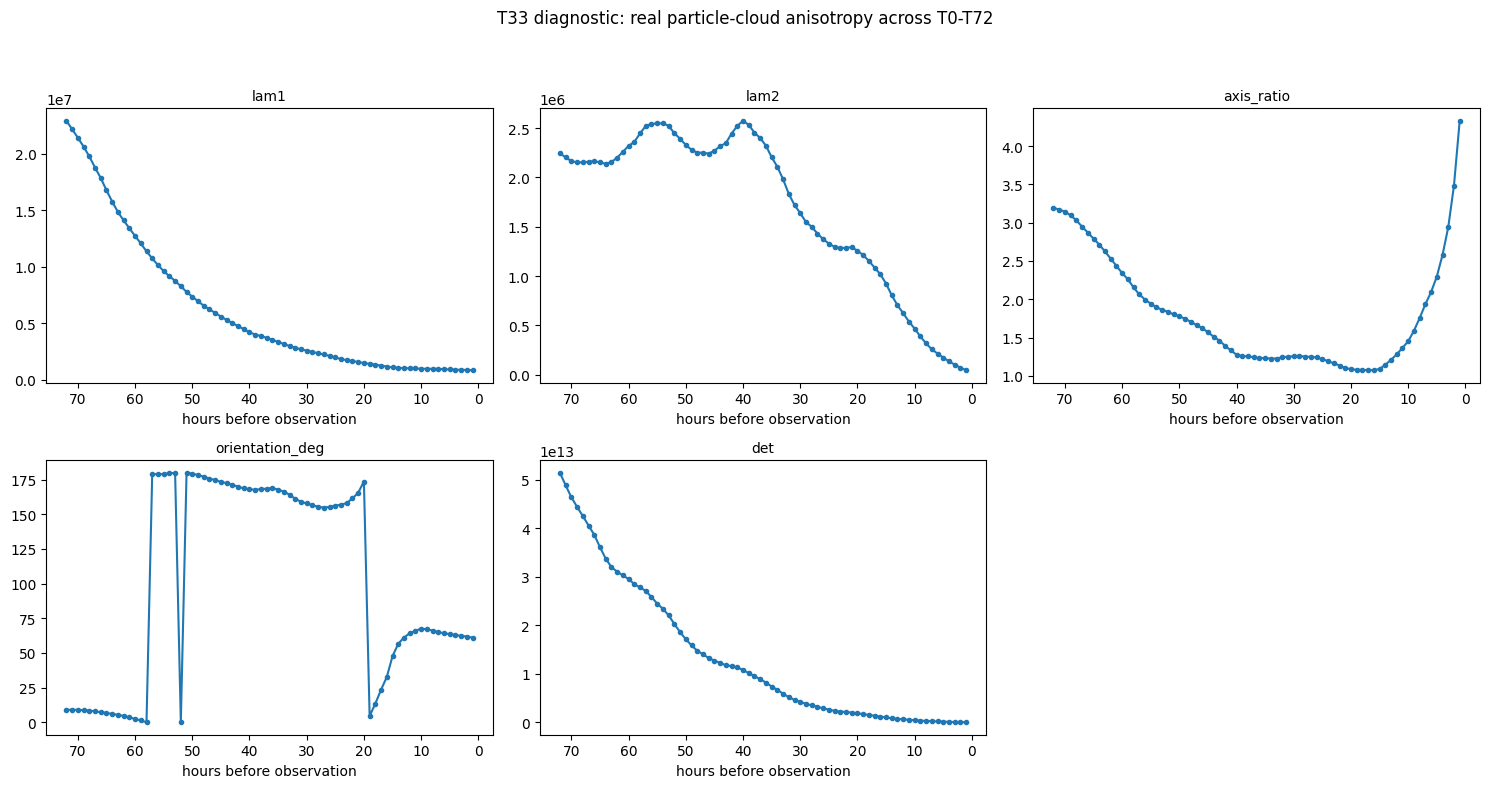

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["lam1", "lam2", "axis_ratio", "orientation_deg", "det"]):
    ax.plot(diag_df["hours_before_obs"], diag_df[col], "-o", markersize=3)
    ax.set_xlabel("hours before observation"); ax.set_title(col, fontsize=10)
    ax.invert_xaxis()
axes.ravel()[-1].axis("off")
fig.suptitle("T33 diagnostic: real particle-cloud anisotropy across T0-T72", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T33_anisotropy_characterization.png"), dpi=100)
plt.show()

### 2-4. Isotropic vs. anisotropic (MC) expected-concentration model vs. REAL empirical fraction

The empirical fraction is measured directly from the real particle positions -- zero
modeling assumptions. Whichever model (isotropic or anisotropic) tracks it more closely
is the statistically more appropriate one for THIS real data.

In [12]:
err_iso = diag_df["p_iso"] - diag_df["p_empirical"]
err_aniso = diag_df["p_aniso"] - diag_df["p_empirical"]
print(f"isotropic model error   (p_iso - p_empirical):   mean={err_iso.mean():+.4f}  MAE={err_iso.abs().mean():.4f}  std={err_iso.std():.4f}")
print(f"anisotropic model error (p_aniso - p_empirical): mean={err_aniso.mean():+.4f}  MAE={err_aniso.abs().mean():.4f}  std={err_aniso.std():.4f}")
print()
corr_err_iso_age = float(np.corrcoef(diag_df["hours_before_obs"], err_iso)[0, 1])
corr_err_aniso_age = float(np.corrcoef(diag_df["hours_before_obs"], err_aniso)[0, 1])
print(f"correlation(age, isotropic model error)   = {corr_err_iso_age:+.3f}")
print(f"correlation(age, anisotropic model error) = {corr_err_aniso_age:+.3f}")

isotropic model error   (p_iso - p_empirical):   mean=+0.0052  MAE=0.0252  std=0.0277
anisotropic model error (p_aniso - p_empirical): mean=+0.0204  MAE=0.0264  std=0.0290

correlation(age, isotropic model error)   = -0.895
correlation(age, anisotropic model error) = -0.819


In [13]:
from scipy.stats import spearmanr

corr_iso_pearson = float(np.corrcoef(diag_df["hours_before_obs"], diag_df["disp_score_iso"])[0, 1])
corr_iso_spearman = float(spearmanr(diag_df["hours_before_obs"], diag_df["disp_score_iso"]).correlation)
corr_aniso_pearson = float(np.corrcoef(diag_df["hours_before_obs"], diag_df["disp_score_aniso"])[0, 1])
corr_aniso_spearman = float(spearmanr(diag_df["hours_before_obs"], diag_df["disp_score_aniso"]).correlation)

print(f"{'':30s} {'Pearson':>10s} {'Spearman':>10s}")
print(f"{'current ISOTROPIC score':30s} {corr_iso_pearson:>10.3f} {corr_iso_spearman:>10.3f}")
print(f"{'diagnostic ANISOTROPIC score':30s} {corr_aniso_pearson:>10.3f} {corr_aniso_spearman:>10.3f}")

                                  Pearson   Spearman
current ISOTROPIC score             0.863      0.862
diagnostic ANISOTROPIC score        0.923      0.893


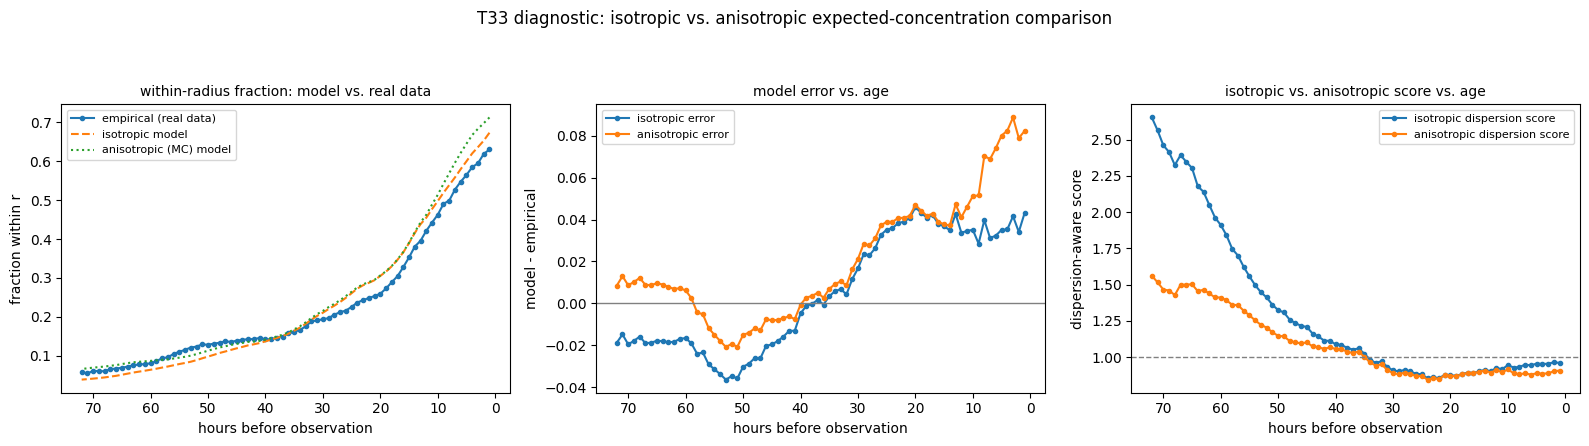

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(diag_df["hours_before_obs"], diag_df["p_empirical"], "-o", markersize=3, label="empirical (real data)")
axes[0].plot(diag_df["hours_before_obs"], diag_df["p_iso"], "--", label="isotropic model")
axes[0].plot(diag_df["hours_before_obs"], diag_df["p_aniso"], ":", label="anisotropic (MC) model")
axes[0].set_xlabel("hours before observation"); axes[0].set_ylabel("fraction within r")
axes[0].set_title("within-radius fraction: model vs. real data", fontsize=10)
axes[0].legend(fontsize=8); axes[0].invert_xaxis()

axes[1].plot(diag_df["hours_before_obs"], err_iso, "-o", markersize=3, label="isotropic error")
axes[1].plot(diag_df["hours_before_obs"], err_aniso, "-o", markersize=3, label="anisotropic error")
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("model - empirical")
axes[1].set_title("model error vs. age", fontsize=10)
axes[1].legend(fontsize=8); axes[1].invert_xaxis()

axes[2].plot(diag_df["hours_before_obs"], diag_df["disp_score_iso"], "-o", markersize=3, label="isotropic dispersion score")
axes[2].plot(diag_df["hours_before_obs"], diag_df["disp_score_aniso"], "-o", markersize=3, label="anisotropic dispersion score")
axes[2].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[2].set_xlabel("hours before observation"); axes[2].set_ylabel("dispersion-aware score")
axes[2].set_title("isotropic vs. anisotropic score vs. age", fontsize=10)
axes[2].legend(fontsize=8); axes[2].invert_xaxis()

fig.suptitle("T33 diagnostic: isotropic vs. anisotropic expected-concentration comparison", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T33_isotropic_vs_anisotropic.png"), dpi=100)
plt.show()

## 5 (synthetic validation A-D). Isotropic vs. anisotropic model on controlled synthetic clouds

A: isotropic Gaussian. B: strongly elongated Gaussian. C: same as B, rotated 45 deg.
D: same relative concentration under different covariance scales.

In [15]:
def rotation_matrix(deg):
    th = np.radians(deg)
    return np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])

R_TEST = 1000.0

# A: isotropic, sigma=1000m both axes
cov_A = np.diag([1000.0**2, 1000.0**2])
# B: strongly elongated, major axis sigma=3000m, minor axis sigma=500m, axis-aligned
cov_B = np.diag([3000.0**2, 500.0**2])
# C: same shape as B, rotated 45 degrees
Rmat = rotation_matrix(45.0)
cov_C = Rmat @ cov_B @ Rmat.T

for name, cov in [("A (isotropic)", cov_A), ("B (elongated, axis-aligned)", cov_B), ("C (elongated, rotated 45deg)", cov_C)]:
    lam1, lam2, ratio, orient, det = characterize_anisotropy(cov)
    p_iso = p_within_r_isotropic(cov, R_TEST)
    p_aniso = p_within_r_anisotropic_mc(cov, R_TEST, seed=1)
    print(f"{name:32s} lam1={lam1:>10.0f} lam2={lam2:>10.0f} ratio={ratio:>5.2f} orient={orient:>6.1f}deg "
          f"| p_iso={p_iso:.4f} p_aniso={p_aniso:.4f} diff={p_iso-p_aniso:+.4f}")

A (isotropic)                    lam1=   1000000 lam2=   1000000 ratio= 1.00 orient=  90.0deg | p_iso=0.3935 p_aniso=0.3952 diff=-0.0017
B (elongated, axis-aligned)      lam1=   9000000 lam2=    250000 ratio= 6.00 orient=   0.0deg | p_iso=0.1025 p_aniso=0.2231 diff=-0.1206
C (elongated, rotated 45deg)     lam1=   9000000 lam2=    250000 ratio= 6.00 orient=  45.0deg | p_iso=0.1025 p_aniso=0.2231 diff=-0.1206


In [16]:
# D: same relative concentration (2x expected), different covariance SCALES (isotropic, two magnitudes)
cov_D_small = np.diag([500.0**2, 500.0**2])
cov_D_large = np.diag([2500.0**2, 2500.0**2])

for name, cov in [("D-small", cov_D_small), ("D-large", cov_D_large)]:
    p_aniso = p_within_r_anisotropic_mc(cov, R_TEST, seed=2)
    n_total = 1000
    d_expected = n_total * p_aniso
    d_actual = 2.0 * d_expected  # constructed to be exactly 2x expected, for BOTH scales
    score = d_actual / d_expected
    print(f"{name:10s} p_aniso={p_aniso:.4f}  d_expected={d_expected:.2f}  d_actual={d_actual:.2f}  score={score:.4f}")

D-small    p_aniso=0.8650  d_expected=864.97  d_actual=1729.93  score=2.0000
D-large    p_aniso=0.0771  d_expected=77.07  d_actual=154.14  score=2.0000


## 6. Does the anisotropic formulation still satisfy the original T33 requirement?

Two synthetic ANISOTROPIC timestamps, very different covariance scale/shape, both
constructed to have the SAME relative concentration (2x their own anisotropic
expectation) -- scores must match despite very different raw magnitudes.

In [17]:
cov_t1 = np.diag([600.0**2, 900.0**2])   # timestamp 1: modest anisotropic spread
cov_t2 = Rmat @ np.diag([2800.0**2, 1200.0**2]) @ Rmat.T   # timestamp 2: large, rotated, more anisotropic

n1, n2 = 300, 300
p1 = p_within_r_anisotropic_mc(cov_t1, R_TEST, seed=3)
p2 = p_within_r_anisotropic_mc(cov_t2, R_TEST, seed=4)
d_exp1, d_exp2 = n1 * p1, n2 * p2
d_act1, d_act2 = 1.7 * d_exp1, 1.7 * d_exp2  # same relative concentration (1.7x) at both

score1, score2 = d_act1 / d_exp1, d_act2 / d_exp2
print(f"timestamp 1: p_aniso={p1:.4f} d_expected={d_exp1:.2f} d_actual={d_act1:.2f} score={score1:.4f}")
print(f"timestamp 2: p_aniso={p2:.4f} d_expected={d_exp2:.2f} d_actual={d_act2:.2f} score={score2:.4f}")
print(f"raw actual density ratio (t1/t2): {d_act1/d_act2:.3f}x  (confirms very different raw magnitudes)")
print(f"scores equal: {np.isclose(score1, score2)}")

timestamp 1: p_aniso=0.5884 d_expected=176.52 d_actual=300.08 score=1.7000
timestamp 2: p_aniso=0.1354 d_expected=40.63 d_actual=69.08 score=1.7000
raw actual density ratio (t1/t2): 4.344x  (confirms very different raw magnitudes)
scores equal: True


## Diagnostic summary (2026-09-24) -- no production code changed

This section was added purely to compare the current isotropic model against an
anisotropic (Monte Carlo) alternative and against the real, model-free empirical
within-radius fraction. `iste/phase3_dispersion.py` was not modified; no formulation
was selected here based on which produces a smaller age correlation -- see the written
report for the goodness-of-fit-based conclusion.

## 7. Final requested review diagnostic: empirical within-timestamp null

**No changes to `iste/phase3_dispersion.py`; production weights/formula untouched.**
Goal: determine whether the `+0.86` age trend is caused by the GAUSSIAN
expected-concentration model specifically, or persists even when "expected
concentration" is estimated directly from the real particle population at each
timestamp, with zero distributional assumption.

**Empirical null -- exact definition.** For every VALID particle `i` at timestamp `t`,
let `local_count_i` = the number of particles (including itself) within radius `r`
(the SAME `NEIGHBORHOOD_RADIUS_M` already used everywhere in T16/T33 -- not a new
parameter) of particle `i`'s own real position, computed via the SAME T15 KD-tree
(`ParticleNeighborhoodIndex`, already built for this timestamp -- reused, not rebuilt).

```text
D_expected_empirical(t) = median_i( local_count_i )   for i = 1..N_valid(t)
empirical_null_score    = D_actual_at_candidate_peak / D_expected_empirical(t)
```

This is "the typical (median) local density an UNREMARKABLE member of this EXACT real
population shows", using only that timestamp's own actual particle count, positions,
extent, and dispersion -- no Gaussian, no covariance, no shape assumption of any kind.
The median (rather than mean) is used as the primary statistic because local-count
distributions are right-skewed (a few particles near the true peak have much higher
local counts than most); mean is also reported for transparency. Introduces exactly
ZERO new hyperparameters -- it reuses the same `r` already used by T16's `D` and by
T33's own Gaussian `D_expected`.

In [18]:
t0 = time.time()
empirical_rows = []
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    candidates_here = find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config)
    if not candidates_here:
        continue
    top_candidate = max(candidates_here, key=lambda c: c.support_score)

    cloud_stats = compute_timestamp_cloud_stats(records, t_s)
    if cloud_stats.covariance_state != "full_rank":
        continue
    gaussian_result = compute_dispersion_aware_score(top_candidate, cloud_stats, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M)

    # empirical null: reuse the ALREADY-BUILT T15 KD-tree, self-query every real particle
    positions = np.column_stack([index.x_m, index.y_m])
    local_counts = index._tree.query_ball_point(positions, NEIGHBORHOOD_RADIUS_M, return_length=True)
    d_expected_empirical_median = float(np.median(local_counts))
    d_expected_empirical_mean = float(np.mean(local_counts))

    empirical_null_score = (
        top_candidate.density_score / d_expected_empirical_median
        if d_expected_empirical_median > 0 else np.nan
    )

    hours_before_obs = float((t_obs - t_s) / np.timedelta64(1, "h"))
    empirical_rows.append(dict(
        hours_before_obs=hours_before_obs,
        d_actual=top_candidate.density_score,
        n_total=cloud_stats.n_particles,
        d_expected_gaussian=gaussian_result.expected_density,
        gaussian_score=gaussian_result.dispersion_aware_score,
        d_expected_empirical_median=d_expected_empirical_median,
        d_expected_empirical_mean=d_expected_empirical_mean,
        empirical_null_score=empirical_null_score,
    ))
t1 = time.time()
print(f"processed {len(empirical_rows)} real historical timestamps in {t1-t0:.1f}s")

processed 72 real historical timestamps in 129.9s


### 7-9. Compare actual / Gaussian-expected / empirical-expected concentration, and both scores

In [19]:
emp_df = pd.DataFrame(empirical_rows)

corr_gauss_pearson = float(np.corrcoef(emp_df["hours_before_obs"], emp_df["gaussian_score"])[0, 1])
corr_gauss_spearman = float(spearmanr(emp_df["hours_before_obs"], emp_df["gaussian_score"]).correlation)
corr_emp_pearson = float(np.corrcoef(emp_df["hours_before_obs"], emp_df["empirical_null_score"])[0, 1])
corr_emp_spearman = float(spearmanr(emp_df["hours_before_obs"], emp_df["empirical_null_score"]).correlation)

def _stats(s):
    return dict(mean=s.mean(), median=s.median(), p10=s.quantile(0.10), p90=s.quantile(0.90), min=s.min(), max=s.max())

gauss_stats = _stats(emp_df["gaussian_score"])
emp_stats = _stats(emp_df["empirical_null_score"])

print(f"{'':30s} {'Pearson':>9s} {'Spearman':>9s} {'mean':>8s} {'median':>8s} {'p10':>8s} {'p90':>8s} {'min':>8s} {'max':>8s}")
print(f"{'current GAUSSIAN score':30s} {corr_gauss_pearson:>9.3f} {corr_gauss_spearman:>9.3f} "
      f"{gauss_stats['mean']:>8.3f} {gauss_stats['median']:>8.3f} {gauss_stats['p10']:>8.3f} {gauss_stats['p90']:>8.3f} "
      f"{gauss_stats['min']:>8.3f} {gauss_stats['max']:>8.3f}")
print(f"{'EMPIRICAL-NULL score':30s} {corr_emp_pearson:>9.3f} {corr_emp_spearman:>9.3f} "
      f"{emp_stats['mean']:>8.3f} {emp_stats['median']:>8.3f} {emp_stats['p10']:>8.3f} {emp_stats['p90']:>8.3f} "
      f"{emp_stats['min']:>8.3f} {emp_stats['max']:>8.3f}")

                                 Pearson  Spearman     mean   median      p10      p90      min      max
current GAUSSIAN score             0.863     0.862    1.298    1.056    0.883    2.291    0.854    2.652
EMPIRICAL-NULL score               0.951     0.943    1.908    2.030    1.424    2.370    1.242    2.426


### 10. Gaussian expected vs. empirical expected -- do they diverge more with age?

In [20]:
relative_diff = (emp_df["d_expected_gaussian"] - emp_df["d_expected_empirical_median"]) / emp_df["d_expected_empirical_median"]
corr_reldiff_age = float(np.corrcoef(emp_df["hours_before_obs"], relative_diff)[0, 1])
print(f"(D_expected_gaussian - D_expected_empirical) / D_expected_empirical:")
print(f"  mean={relative_diff.mean():+.3f}  std={relative_diff.std():.3f}")
print(f"  correlation with age: {corr_reldiff_age:+.3f}")
print()
print("sample rows:")
cols = ["hours_before_obs", "d_actual", "d_expected_gaussian", "d_expected_empirical_median", "gaussian_score", "empirical_null_score"]
print(emp_df[cols].iloc[np.linspace(0, len(emp_df) - 1, 12).astype(int)].round(3).to_string(index=False))

(D_expected_gaussian - D_expected_empirical) / D_expected_empirical:
  mean=+0.581  std=0.323
  correlation with age: -0.510

sample rows:
 hours_before_obs  d_actual  d_expected_gaussian  d_expected_empirical_median  gaussian_score  empirical_null_score
              1.0    2123.0             2212.366                       1709.0           0.960                 1.242
              7.0    1740.0             1835.514                       1244.0           0.948                 1.399
             13.0    1300.0             1440.311                        827.0           0.903                 1.572
             20.0     878.0             1003.761                        545.0           0.875                 1.611
             26.0     724.0              818.591                        451.0           0.884                 1.605
             33.0     575.0              599.392                        315.0           0.959                 1.825
             39.0     505.0              466.020 

### 13. Required plots

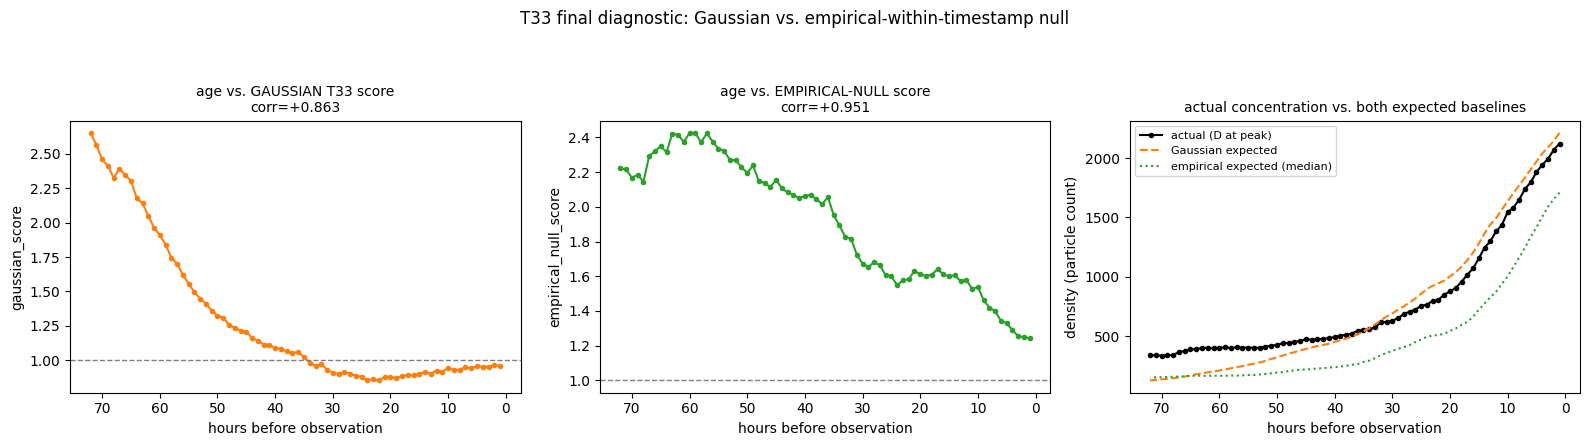

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(emp_df["hours_before_obs"], emp_df["gaussian_score"], "-o", markersize=3, color="tab:orange")
axes[0].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("hours before observation"); axes[0].set_ylabel("gaussian_score")
axes[0].set_title(f"age vs. GAUSSIAN T33 score\ncorr={corr_gauss_pearson:+.3f}", fontsize=10)
axes[0].invert_xaxis()

axes[1].plot(emp_df["hours_before_obs"], emp_df["empirical_null_score"], "-o", markersize=3, color="tab:green")
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("empirical_null_score")
axes[1].set_title(f"age vs. EMPIRICAL-NULL score\ncorr={corr_emp_pearson:+.3f}", fontsize=10)
axes[1].invert_xaxis()

axes[2].plot(emp_df["hours_before_obs"], emp_df["d_actual"], "-o", markersize=3, label="actual (D at peak)", color="black")
axes[2].plot(emp_df["hours_before_obs"], emp_df["d_expected_gaussian"], "--", label="Gaussian expected", color="tab:orange")
axes[2].plot(emp_df["hours_before_obs"], emp_df["d_expected_empirical_median"], ":", label="empirical expected (median)", color="tab:green")
axes[2].set_xlabel("hours before observation"); axes[2].set_ylabel("density (particle count)")
axes[2].set_title("actual concentration vs. both expected baselines", fontsize=10)
axes[2].legend(fontsize=8); axes[2].invert_xaxis()

fig.suptitle("T33 final diagnostic: Gaussian vs. empirical-within-timestamp null", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T33_empirical_null_diagnostic.png"), dpi=100)
plt.show()

### 14. Computational stability / new hyperparameters

In [22]:
n_nan_gaussian = int(emp_df["gaussian_score"].isna().sum())
n_nan_empirical = int(emp_df["empirical_null_score"].isna().sum())
n_zero_median = int((emp_df["d_expected_empirical_median"] <= 0).sum())
print(f"NaN gaussian_score: {n_nan_gaussian}/{len(emp_df)}")
print(f"NaN empirical_null_score: {n_nan_empirical}/{len(emp_df)}")
print(f"timestamps with zero empirical median (degenerate): {n_zero_median}/{len(emp_df)}")
print(f"new hyperparameters introduced by the empirical null: 0 (reuses the existing neighborhood_radius_m only)")
print(f"total diagnostic runtime: {t1 - t0:.1f}s for {len(empirical_rows)} timestamps (stable, no retries/failures)")

NaN gaussian_score: 0/72
NaN empirical_null_score: 0/72
timestamps with zero empirical median (degenerate): 0/72
new hyperparameters introduced by the empirical null: 0 (reuses the existing neighborhood_radius_m only)
total diagnostic runtime: 129.9s for 72 timestamps (stable, no retries/failures)


### 15. Conclusion

In [23]:
print(f"age correlation -- current GAUSSIAN score:   Pearson={corr_gauss_pearson:+.3f}  Spearman={corr_gauss_spearman:+.3f}")
print(f"age correlation -- EMPIRICAL-NULL score:      Pearson={corr_emp_pearson:+.3f}  Spearman={corr_emp_spearman:+.3f}")
print(f"relative gap between Gaussian and empirical expected baselines, correlation with age: {corr_reldiff_age:+.3f}")

age correlation -- current GAUSSIAN score:   Pearson=+0.863  Spearman=+0.862
age correlation -- EMPIRICAL-NULL score:      Pearson=+0.951  Spearman=+0.943
relative gap between Gaussian and empirical expected baselines, correlation with age: -0.510


## Diagnostic summary (2026-09-24) -- no production code changed

This section (7) was added purely to test whether T33's Gaussian expected-concentration
model is the cause of the flagged age correlation, by replacing it with a
zero-assumption empirical alternative derived directly from each timestamp's own real
particle population. `iste/phase3_dispersion.py` was not modified; no production
weights changed. See the written report for the final categorical conclusion (A/B/C).